In [ ]:
!pip install roboflow

from getpass import getpass
from roboflow import Roboflow

# Enter your Roboflow API key when prompted (never hard-code it in the notebook)
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("roboflow-58fyf").project("rock-paper-scissors-sxsw")
version = project.version(1)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 110.4 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to rock-paper-scissors-1 in yolov8:: 100%|██████████| 2270/2270 [00:00<00:00, 5920.91it/s]


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

# Load a model
model = YOLO('yolov8n.pt')  # load a pretrained

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
Results=model.train(data= "/content/rock-paper-scissors-1/data.yaml", epochs=100 , imgsz=640)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rock-paper-scissors-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fa

### عرض نتائج التدريب والمقاييس
سنقوم الآن بعرض الصور الناتجة عن التدريب مثل منحنيات الخسارة (loss curves) ودقة النموذج والمقاييس الأخرى المخزنة في مجلد المخرجات.

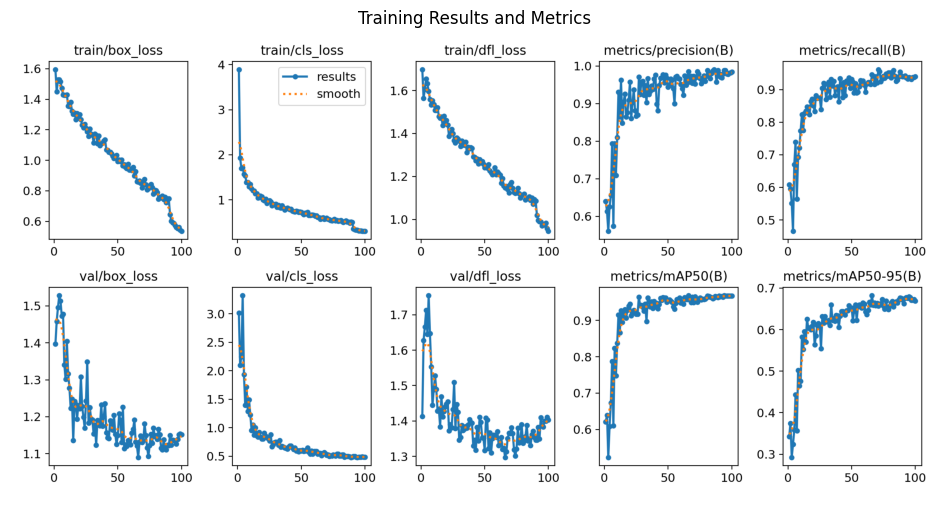

In [ ]:
import os
import matplotlib.pyplot as plt
import cv2

# تحديد مسار المخرجات
results_dir = '/content/runs/detect/train'

# عرض صورة نتائج التدريب العامة
results_png = os.path.join(results_dir, 'results.png')
if os.path.exists(results_png):
    img = cv2.imread(results_png)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 12))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title('Training Results and Metrics')
    plt.show()
else:
    print("لم يتم العثور على ملف results.png")

### تشغيل التنبؤ (Inference) على صور الاختبار
سنستخدم أفضل الأوزان الناتجة عن التدريب (`best.pt`) للقيام بالتنبؤ على صور من مجلد التحقق وعرض النتائج بصرياً.


0: 480x640 (no detections), 7.9ms
1: 480x640 1 Paper, 7.9ms
2: 480x640 1 Rock, 7.9ms
Speed: 0.7ms preprocess, 7.9ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict


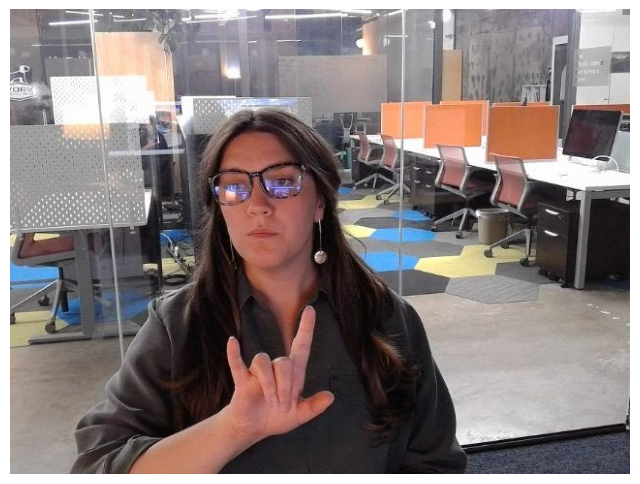

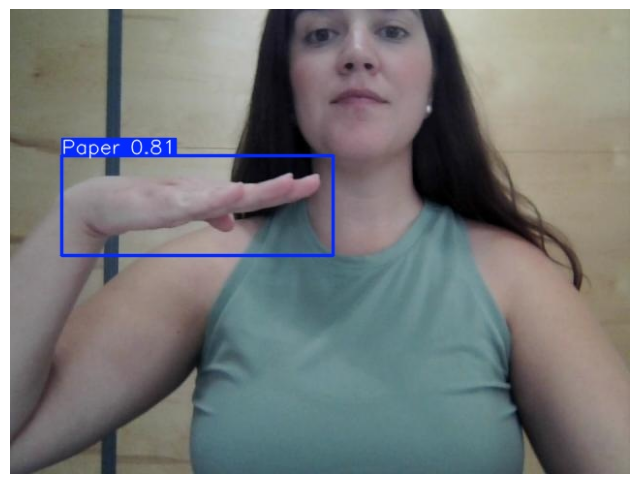

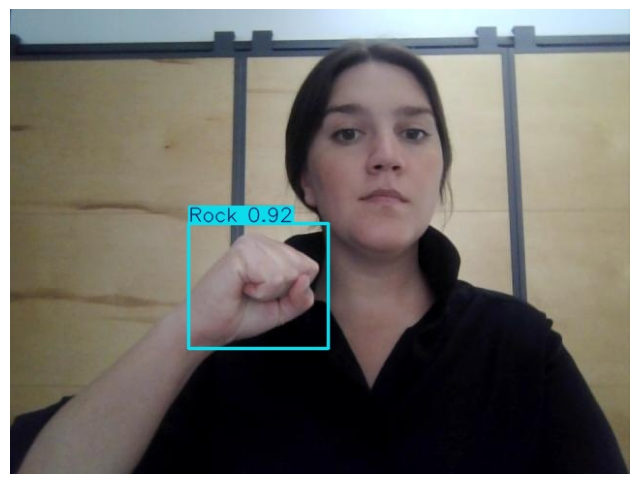

In [ ]:
from ultralytics import YOLO
import glob
import random

# تحميل النموذج المدرب بأفضل الأوزان
best_model = YOLO('/content/runs/detect/train/weights/best.pt')

# جلب مسارات صور التحقق (Validation)
val_images = glob.glob('/content/rock-paper-scissors-1/valid/images/*.jpg')

if val_images:
    # اختيار 3 صور عشوائية للتجربة
    sample_images = random.sample(val_images, min(3, len(val_images)))

    # القيام بالتنبؤ وعرض النتائج
    results = best_model.predict(source=sample_images, save=True, conf=0.5)

    # عرض الصور المتنبأ بها
    for res in results:
        # الحصول على مسار الصورة المحفوظة بالنتيجة
        saved_path = os.path.join(res.save_dir, os.path.basename(res.path))
        if os.path.exists(saved_path):
            img = cv2.imread(saved_path)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.figure(figsize=(8, 8))
            plt.imshow(img_rgb)
            plt.axis('off')
            plt.show()
else:
    print("لم يتم العثور على صور في مجلد التحقق.")